<a href="https://colab.research.google.com/github/joao-araujoo/calculo-numerico/blob/main/Atividade_Interpolacao_Polinomial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade: Interpolação Polinomial

Cálculo Numérico

Integrantes:
- João Pedro Araujo
- Rafael Augusto Guimarães

## 1. Ideia central

Uma situação em que seria útil estimar um valor entre duas medições é a temperatura de uma cidade medida de hora em hora. Se temos a temperatura às 14h e às 15h, dá para estimar como estava às 14h30.

Essa estimativa pode ficar pouco confiável se as medições estiverem muito espaçadas, se acontecer alguma mudança brusca entre elas (uma chuva repentina, por exemplo) ou se os próprios dados tiverem erro de medição.

## 2. Dados, nós e grau

Previsão: se acrescentarmos um ponto novo, o polinômio continua tendo que passar pelos pontos antigos, já que ele precisa passar por todos os pontos dados. Mas o formato da curva pode mudar bastante, porque agora tem mais um ponto para respeitar e o grau do polinômio normalmente aumenta. A curva só fica igual se o ponto novo já estiver em cima da curva anterior.

## 3. Primeiro exemplo

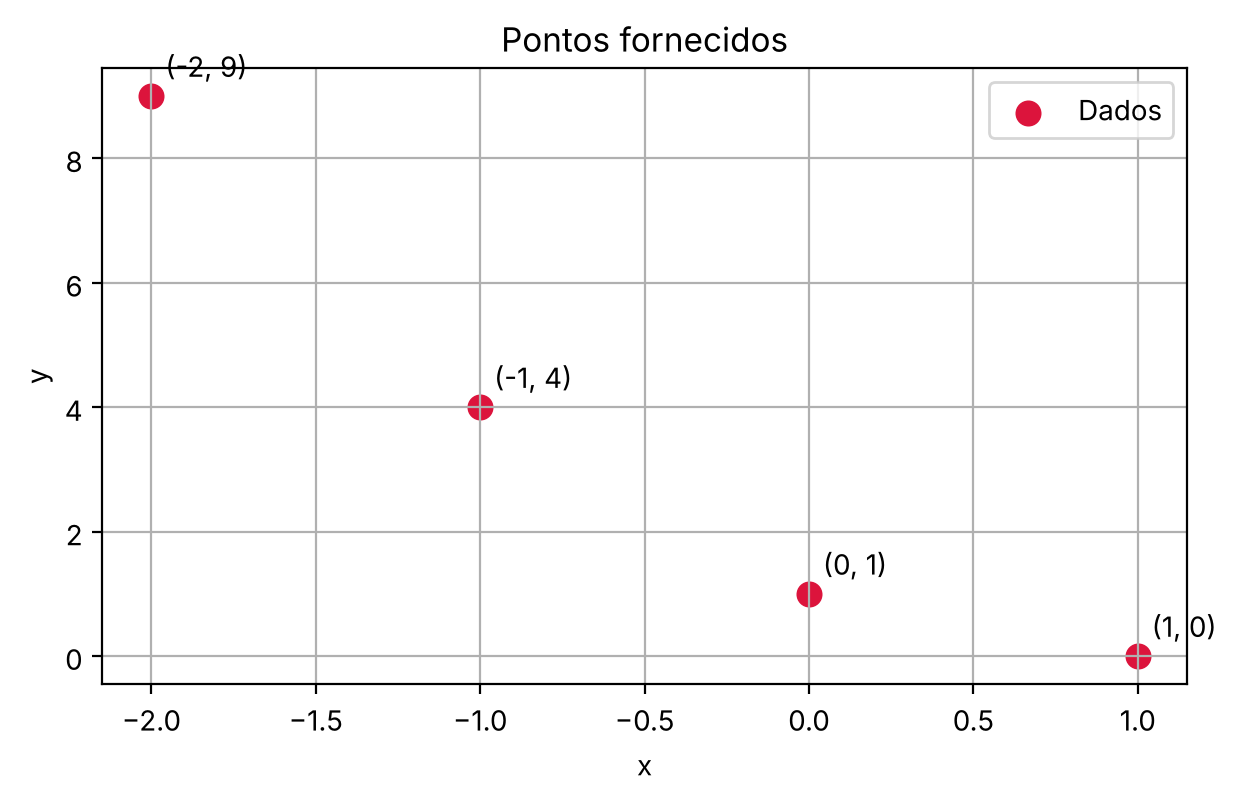

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([-2, -1, 0, 1], dtype=float)
y = np.array([9, 4, 1, 0], dtype=float)

plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="crimson", s=70, label="Dados")
for xi, yi in zip(x, y):
    plt.annotate(f"({xi:g}, {yi:g})", (xi, yi), xytext=(5, 7), textcoords="offset points")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Pontos fornecidos")
plt.grid(True); plt.legend(); plt.show()

Os valores de y diminuem conforme x aumenta (9, 4, 1, 0), mas cada vez diminuem menos: as quedas são de 5, depois 3 e depois 1. Por isso a curva não pode ser uma reta, já que numa reta as quedas seriam todas iguais. O formato lembra uma parábola.

Existem infinitas curvas que passam por esses quatro pontos. O que é único é o polinômio de grau no máximo 3 que passa por eles.

## 4. Construindo o polinômio

In [ ]:
polinomio = np.polynomial.Polynomial.fit(x, y, deg=len(x)-1).convert()
print(polinomio)
print(polinomio.coef)

1.0 - 2.0·x + 1.0·x² - (4.28226564e-16)·x³
[ 1.00000000e+00 -2.00000000e+00  1.00000000e+00 -4.28226564e-16]


A expressão obtida foi $P(x) = 1 - 2x + x^2$ mais um termo em $x^3$ com coeficiente da ordem de $10^{-16}$.

Esse coeficiente de $x^3$ é praticamente zero e só aparece por causa do arredondamento do computador. Então o polinômio é na verdade $P(x) = x^2 - 2x + 1 = (x-1)^2$, que tem grau 2. Os quatro pontos já estavam em cima de uma parábola, por isso o grau ficou menor que 3.

In [ ]:
valores_nos_nos = polinomio(x)
for xi, yi, pi in zip(x, y, valores_nos_nos):
    print(f"x={xi:5.1f} | dado={yi:10.6f} | P(x)={pi:10.6f} | diferença={abs(yi-pi):.2e}")

x= -2.0 | dado=  9.000000 | P(x)=  9.000000 | diferença=1.78e-15
x= -1.0 | dado=  4.000000 | P(x)=  4.000000 | diferença=1.78e-15
x=  0.0 | dado=  1.000000 | P(x)=  1.000000 | diferença=8.88e-16
x=  1.0 | dado=  0.000000 | P(x)=  0.000000 | diferença=2.89e-15


1. As diferenças são muito pequenas, da ordem de $10^{-15}$. Não dão zero exato por causa do arredondamento, mas na prática são zero.
2. Essa conferência mostra que a curva passa por todos os nós, ou seja, reproduz os dados da tabela.
3. Ela não mostra se os valores entre os nós estão certos, nem se a curva faz sentido fora do intervalo de $-2$ a $1$. Só testa os pontos que a gente já conhecia.

## 5. Visualizar não é o mesmo que validar

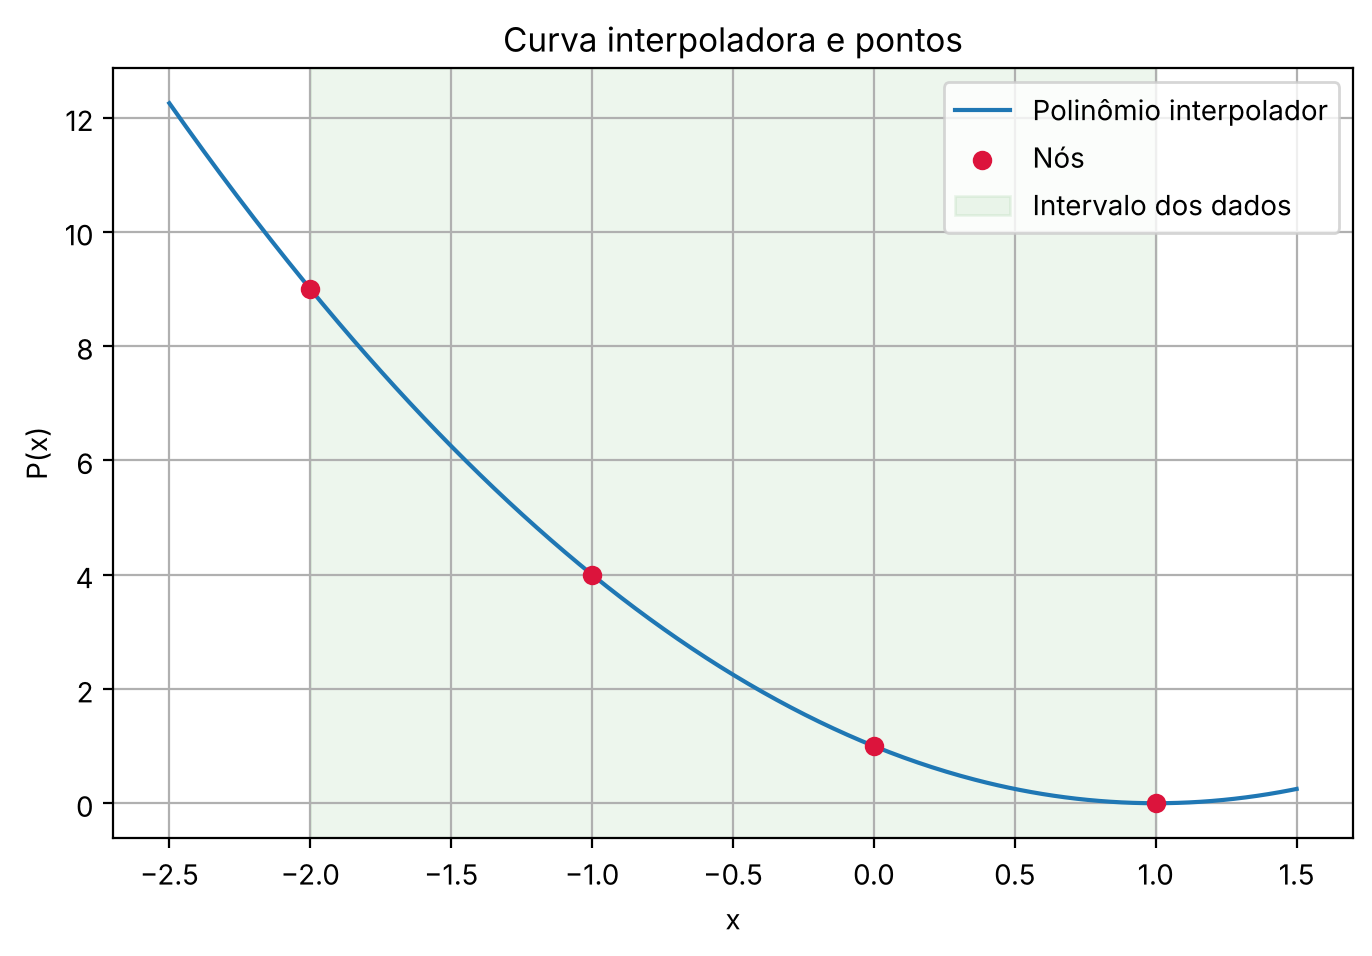

In [ ]:
xx = np.linspace(x.min()-0.5, x.max()+0.5, 400)
plt.figure(figsize=(8, 5))
plt.plot(xx, polinomio(xx), label="Polinômio interpolador")
plt.scatter(x, y, color="crimson", zorder=3, label="Nós")
plt.axvspan(x.min(), x.max(), color="green", alpha=0.07, label="Intervalo dos dados")
plt.xlabel("x"); plt.ylabel("P(x)"); plt.title("Curva interpoladora e pontos")
plt.grid(True); plt.legend(); plt.show()

A curva passa pelos quatro pontos. Fora da faixa verde (antes de $x = -2$ e depois de $x = 1$) ela continua subindo como uma parábola, mas isso não é garantido pelos dados, porque não temos nenhuma medição ali. Esse pedaço do gráfico é só o polinômio se estendendo, não uma informação confiável.

## 6. Valores intermediários

In [ ]:
consultas = np.array([-1.5, -0.5, 0.5, 0.9, 2.0])
for q in consultas:
    tipo = "interpolação" if x.min() <= q <= x.max() else "extrapolação"
    print(f"P({q:4.1f}) = {polinomio(q): .6f}  ({tipo})")

P(-1.5) =  6.250000  (interpolação)
P(-0.5) =  2.250000  (interpolação)
P( 0.5) =  0.250000  (interpolação)
P( 0.9) =  0.010000  (interpolação)
P( 2.0) =  1.000000  (extrapolação)


| x consultado | Estimativa P(x) | Interpolação ou extrapolação? |
|---|---|---|
| $-1{,}5$ | $6{,}25$ | Interpolação |
| $-0{,}5$ | $2{,}25$ | Interpolação |
| $0{,}5$ | $0{,}25$ | Interpolação |
| $0{,}9$ | $0{,}01$ | Interpolação |
| $2{,}0$ | $1{,}00$ | Extrapolação |

O único caso de extrapolação é $x = 2$, porque ele fica fora do intervalo dos nós, que vai de $-2$ a $1$.

### Comparação com outras ferramentas

| Ferramenta e link | Como inserimos os dados | Expressão/resultado | O que foi fácil ou difícil |
|---|---|---|---|
| GeoGebra (https://www.geogebra.org/calculator) | Na barra de entrada: `Polinômio({(-2,9),(-1,4),(0,1),(1,0)})`, depois `f(-1.5)` e `f(0.5)` | $x^2 - 2x + 1$; $f(-1{,}5) = 6{,}25$ e $f(0{,}5) = 0{,}25$ | Fácil de usar e já mostra o gráfico com os pontos. O difícil foi achar o nome do comando. |
| WolframAlpha (https://www.wolframalpha.com) | `interpolating polynomial {{-2,9},{-1,4},{0,1},{1,0}}` | $x^2 - 2x + 1$; valores $6{,}25$ e $0{,}25$ | Aceita o pedido escrito como frase. O chato é que é em inglês e parte dos recursos é paga. |

As duas ferramentas deram o mesmo resultado do nosso código: o polinômio $x^2 - 2x + 1$ e os mesmos valores em $x = -1{,}5$ e $x = 0{,}5$. A única diferença é que o NumPy mostrou aquele coeficiente minúsculo em $x^3$, que é só arredondamento. Bateu porque todas fizeram interpolação polinomial exata, e não regressão ou spline.

## 7. Segundo conjunto: dados de medição

1.2 + 1.11666667·x - 0.45·x² + 0.13333333·x³
Estimativa em x=1.5: 2.312500


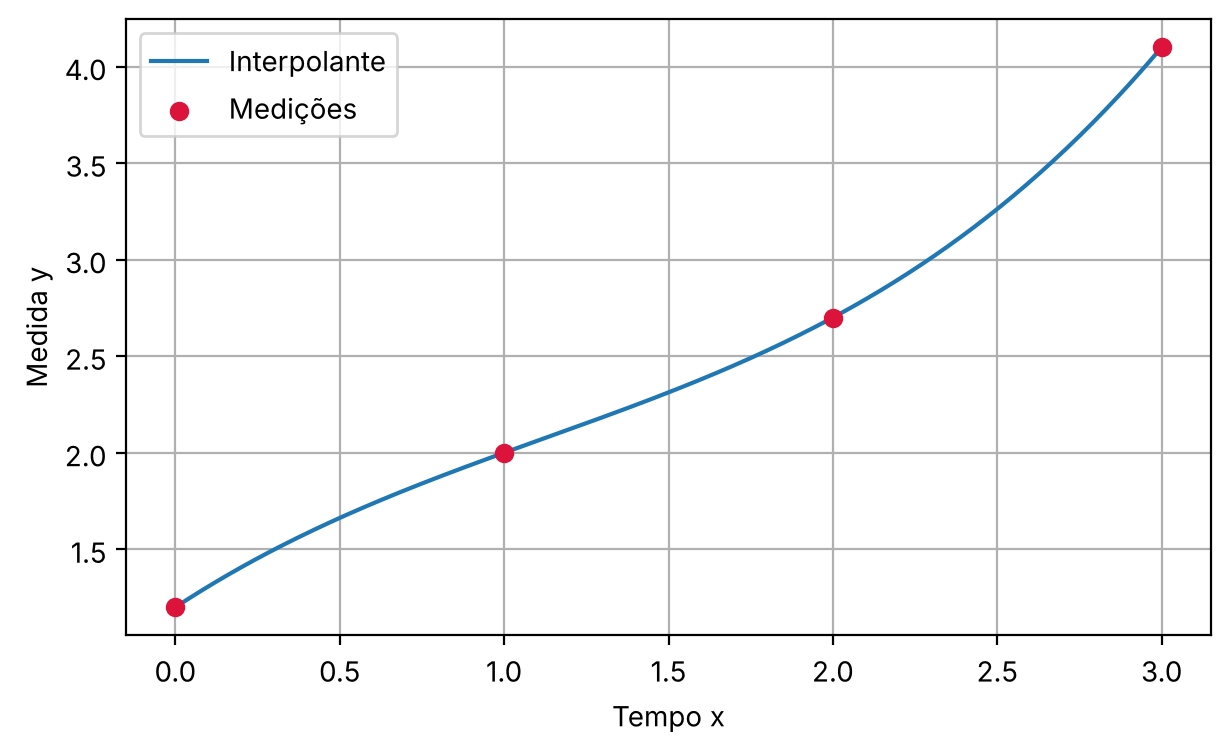

In [ ]:
xB = np.array([0, 1, 2, 3], dtype=float)
yB = np.array([1.2, 2.0, 2.7, 4.1], dtype=float)
pB = np.polynomial.Polynomial.fit(xB, yB, deg=len(xB)-1).convert()
print(pB)
print(f"Estimativa em x=1.5: {pB(1.5):.6f}")

xb_plot = np.linspace(xB.min(), xB.max(), 300)
plt.figure(figsize=(7, 4))
plt.plot(xb_plot, pB(xb_plot), label="Interpolante")
plt.scatter(xB, yB, color="crimson", label="Medições", zorder=3)
plt.xlabel("Tempo x"); plt.ylabel("Medida y"); plt.grid(True); plt.legend(); plt.show()

Sim, $x = 1{,}5$ fica entre os nós $x = 1$ e $x = 2$, então é uma interpolação. A estimativa foi $P(1{,}5) \approx 2{,}3125$, o que faz sentido porque fica entre as medições 2,0 e 2,7.

## 8. Experimento: alterar uma medição

Estimativa original em x=1.5: 2.312499999999999
Estimativa alterada em x=1.5: 2.59375


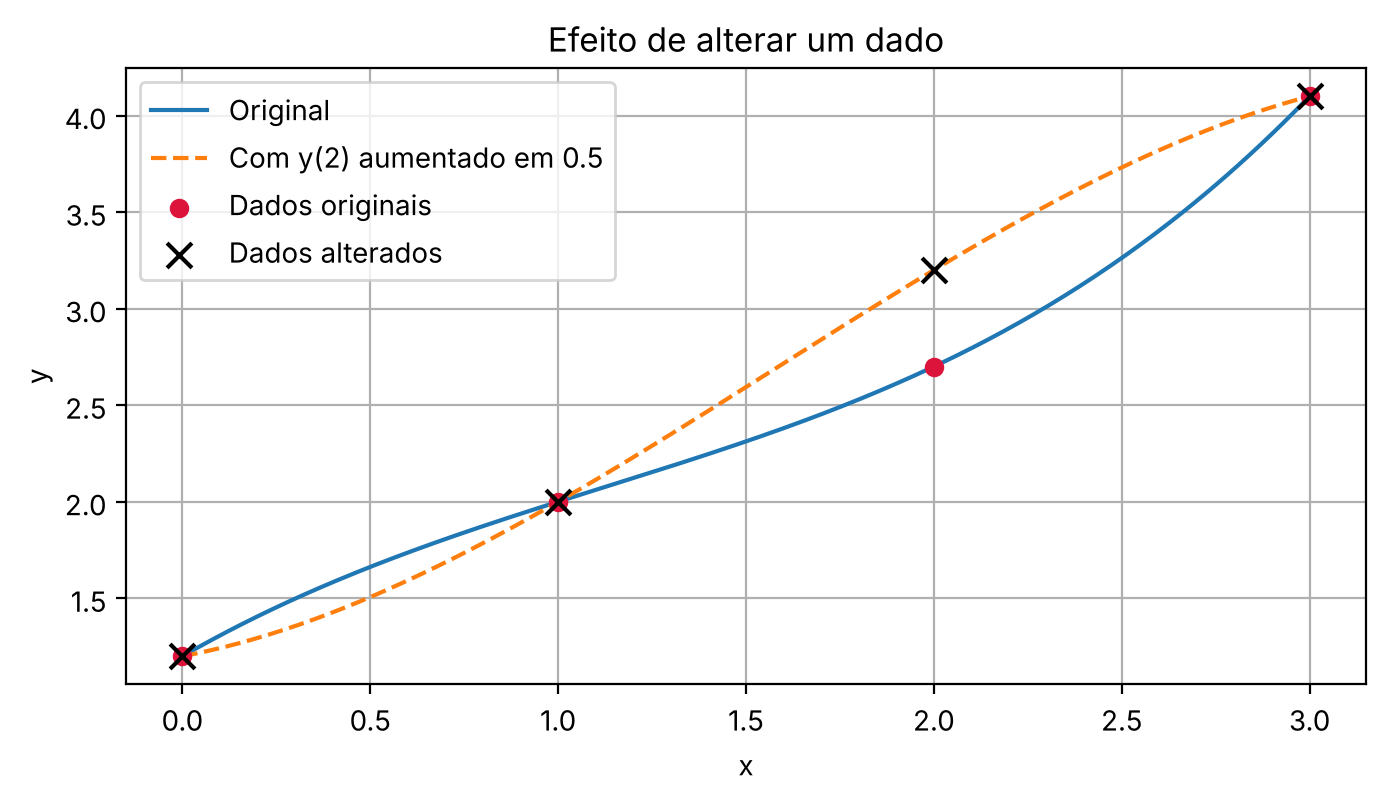

In [ ]:
yB_alterado = yB.copy()
yB_alterado[2] += 0.5
pB_alterado = np.polynomial.Polynomial.fit(xB, yB_alterado, deg=len(xB)-1).convert()
print("Estimativa original em x=1.5:", pB(1.5))
print("Estimativa alterada em x=1.5:", pB_alterado(1.5))

plt.figure(figsize=(8, 4))
plt.plot(xb_plot, pB(xb_plot), label="Original")
plt.plot(xb_plot, pB_alterado(xb_plot), "--", label="Com y(2) aumentado em 0.5")
plt.scatter(xB, yB, color="crimson", zorder=3, label="Dados originais")
plt.scatter(xB, yB_alterado, marker="x", s=80, color="black", zorder=4, label="Dados alterados")
plt.grid(True); plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("Efeito de alterar um dado"); plt.show()

O ponto alterado foi o de $x = 2$, que passou de $y = 2{,}7$ para $y = 3{,}2$.

A estimativa em $x = 1{,}5$ subiu de $2{,}3125$ para $2{,}59375$, uma diferença de cerca de 0,28. Mexer em um único dado já mudou bastante o resultado.

A curva não mudou só perto do ponto alterado. Ela mudou em quase todo o intervalo e só continuou igual nos outros nós ($x = 0$, $x = 1$ e $x = 3$), que não foram alterados. Isso acontece porque o polinômio é calculado usando todos os pontos ao mesmo tempo.

Por isso pequenas incertezas de medição importam: um erro em uma medição só se espalha pela curva inteira e muda as estimativas em outros lugares também.

## 9. Quando o grau alto pode ser um problema

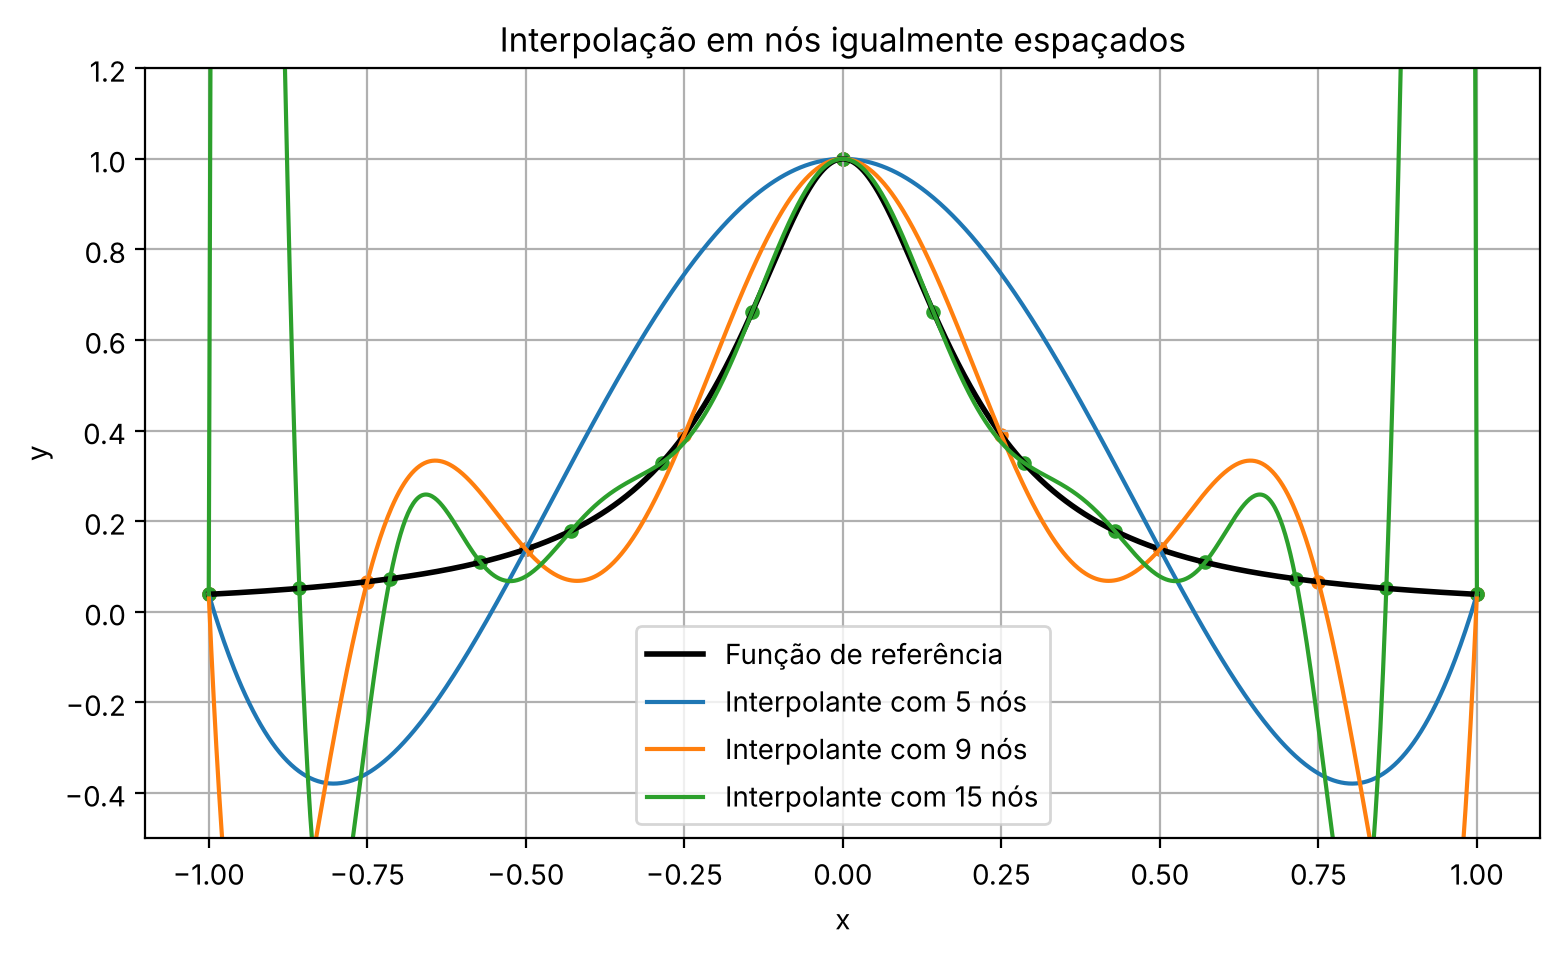

In [ ]:
def f(t):
    return 1/(1+25*t**2)

t_plot = np.linspace(-1, 1, 1000)
plt.figure(figsize=(9, 5))
plt.plot(t_plot, f(t_plot), color="black", linewidth=2, label="Função de referência")
for n in [5, 9, 15]:
    tn = np.linspace(-1, 1, n)
    pn = np.polynomial.Polynomial.fit(tn, f(tn), deg=n-1).convert()
    plt.plot(t_plot, pn(t_plot), label=f"Interpolante com {n} nós")
    plt.scatter(tn, f(tn), s=18)
plt.ylim(-0.5, 1.2); plt.grid(True); plt.legend()
plt.title("Interpolação em nós igualmente espaçados")
plt.xlabel("x"); plt.ylabel("y"); plt.show()

Todas as curvas passam pelos pontos usados para construí-las, dá para ver os pontinhos em cima de cada uma.

Perto das extremidades ($x$ perto de $-1$ e de $1$), quanto mais nós, maior a oscilação. Com 15 nós a curva sobe e desce muito e fica bem longe da função de referência, mesmo passando por todos os pontos. Esse é o fenômeno de Runge.

Com muitos dados, a gente investigaria a interpolação por partes, como as splines cúbicas, que usam polinômios de grau baixo em cada pedaço. Outra opção seria usar nós de Chebyshev, que ficam mais concentrados nas pontas e diminuem a oscilação.

## 10. Interpolação versus regressão

A curva interpoladora do conjunto B foi construída para passar por todos os pontos, independente dos valores. Se uma medição estivesse errada, o polinômio passaria por ela do mesmo jeito, como vimos na seção 8. Então o fato de a curva passar pelos dados não prova que eles estão certos, só mostra que o método fez o que foi pedido.

Para saber se tem ruído, precisaríamos de outras informações, como repetir as medições ou conhecer a precisão do instrumento. Nesse caso, uma regressão poderia representar melhor a tendência geral.

## 11. Síntese

Interpolar é estimar valores dentro do intervalo coberto pelos nós usando uma curva que passa exatamente pelos dados. Extrapolar é usar essa curva fora do intervalo, o que é bem menos confiável. Testamos o GeoGebra e o WolframAlpha, e os dois concordaram com o código: o polinômio foi $x^2 - 2x + 1$, com $P(-1{,}5) = 6{,}25$ e $P(0{,}5) = 0{,}25$. Quando aumentamos em 0,5 a medição em $x = 2$, a estimativa em $x = 1{,}5$ passou de 2,3125 para 2,59375, e a curva mudou em quase todo o intervalo. Uma limitação que observamos é que, com muitos nós igualmente espaçados, o polinômio oscila bastante perto das pontas. Na prática, usaríamos o método para estimar, por exemplo, a temperatura entre duas leituras de um sensor, tomando cuidado para não extrapolar, usar poucos pontos bem distribuídos e lembrar que um erro de medição afeta a curva toda.